In [ ]:
import os
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time
import tensorflow_hub as hub
# import wget

%matplotlib inline
os.environ["TFHUB_DOWNLOAD_PROGRESS"] = "True"

In [ ]:
!wget "https://user-images.githubusercontent.com/12981474/40157448-eff91f06-5953-11e8-9a37-f6b5693fa03f.png" -O original.png

--2025-02-11 15:03:50--  https://user-images.githubusercontent.com/12981474/40157448-eff91f06-5953-11e8-9a37-f6b5693fa03f.png
Resolving user-images.githubusercontent.com (user-images.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to user-images.githubusercontent.com (user-images.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 34146 (33K) [image/png]
Saving to: ‘original.png’

original.png        100%[===================>]  33.35K  --.-KB/s    in 0.001s  

2025-02-11 15:03:50 (32.3 MB/s) - ‘original.png’ saved [34146/34146]



In [ ]:
def preprocess_image(image_path):

  image = tf.image.decode_image(tf.io.read_file(image_path))

  if image.shape[-1] == 4:
    image = image[...,:-1]
  image_size = (tf.convert_to_tensor(image.shape[:-1])//4) * 4
  image = tf.image.crop_to_bounding_box(image,0,0,image_size[0],image_size[1])
  image = tf.cast(image,tf.float32)
  return tf.expand_dims(image,axis=0)


def save_image(image,filename):

  if not isinstance(image,Image.Image):
    image = tf.clip_by_value(image,0,255)
    image = Image.fromarray(tf.cast(image,tf.uint8).numpy())
  image.save("%s.jpg" % filename)
  print("Saved as %s.jpg" % filename)


In [ ]:
def plot_image(image):

  image = np.asarray(image)
  image = tf.clip_by_value(image,0,255)
  image = Image.fromarray(tf.cast(image,tf.uint8).numpy())
  plt.imshow(image)
  plt.title("srgan")
  plt.axis("off")

In [ ]:
# Declaring Constants
IMAGE_PATH = "original.png"
SAVED_MODEL_PATH = "https://tfhub.dev/captain-pool/esrgan-tf2/1"

In [ ]:
image = preprocess_image(IMAGE_PATH)

Saved as Original Image.jpg


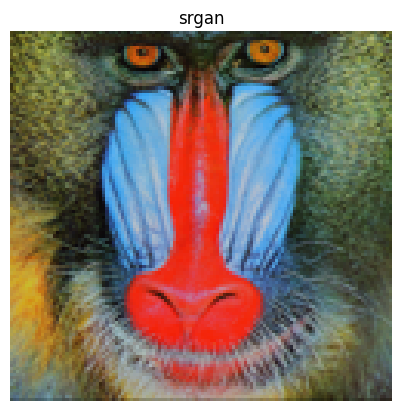

In [ ]:
# Plotting Original Resolution image
plot_image(tf.squeeze(image))
save_image(tf.squeeze(image), filename="Original Image")

In [ ]:
model = hub.load(SAVED_MODEL_PATH)

In [ ]:
start = time.time()
fake_image = model(image)
fake_image = tf.squeeze(fake_image)
print("Time Taken: %f" % (time.time() - start))

Time Taken: 4.190937


Saved as Super Resolution.jpg


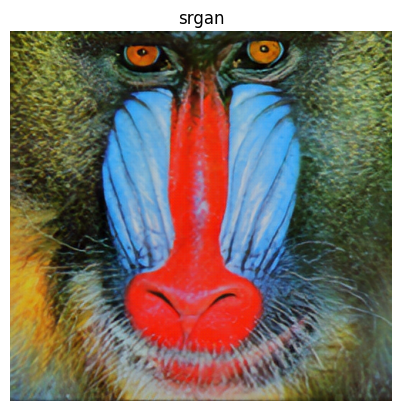

In [ ]:
plot_image(tf.squeeze(fake_image))
save_image(tf.squeeze(fake_image), filename="Super Resolution")

In [ ]:
!wget "https://www.bing.com/ck/a?!&&p=78e7b0009a82c9e32abdb8a900e04af3f8936fda91d8a92d594a39dfe81cce39JmltdHM9MTczOTIzMjAwMA&ptn=3&ver=2&hsh=4&fclid=0c179bbe-24f8-6a38-3775-8873252a6bb3&u=a1L2ltYWdlcy9zZWFyY2g_cT1sb3clMjByZXNvbHV0aW9uJTIwaW1hZ2VzJkZPUk09SVFGUkJBJmlkPTJFMUY3Rjc2RDRBQTk3RjQ3N0M0Mjg5MUE0MzdCMDUwN0JFMzA1QjA&ntb=1" -O test.jpg
IMAGE_PATH = "test.jpg"

--2025-02-11 14:55:11--  https://www.bing.com/ck/a?!&&p=78e7b0009a82c9e32abdb8a900e04af3f8936fda91d8a92d594a39dfe81cce39JmltdHM9MTczOTIzMjAwMA&ptn=3&ver=2&hsh=4&fclid=0c179bbe-24f8-6a38-3775-8873252a6bb3&u=a1L2ltYWdlcy9zZWFyY2g_cT1sb3clMjByZXNvbHV0aW9uJTIwaW1hZ2VzJkZPUk09SVFGUkJBJmlkPTJFMUY3Rjc2RDRBQTk3RjQ3N0M0Mjg5MUE0MzdCMDUwN0JFMzA1QjA&ntb=1
Resolving www.bing.com (www.bing.com)... 23.222.16.75, 23.222.16.74, 23.222.16.89, ...
Connecting to www.bing.com (www.bing.com)|23.222.16.75|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2005 (2.0K) [text/html]
Saving to: ‘test.jpg’

test.jpg            100%[===================>]   1.96K  --.-KB/s    in 0s      

2025-02-11 14:55:11 (98.0 MB/s) - ‘test.jpg’ saved [2005/2005]



In [ ]:
def downscale_image(image):

  image_size = []
  if len(image.shape) == 3:
    image_size = [image.shape[1], image.shape[0]]
  else:
    raise ValueError("Dimension mismatch. Can work only on single image.")

  image = tf.squeeze(
      tf.cast(
          tf.clip_by_value(image, 0, 255), tf.uint8))

  lr_image = np.asarray(
    Image.fromarray(image.numpy())
    .resize([image_size[0] // 4, image_size[1] // 4],
              Image.BICUBIC))

  lr_image = tf.expand_dims(lr_image, 0)
  lr_image = tf.cast(lr_image, tf.float32)
  return lr_image

In [ ]:
image = preprocess_image(IMAGE_PATH)

In [ ]:
lr_image = downscale_image(tf.squeeze(image))

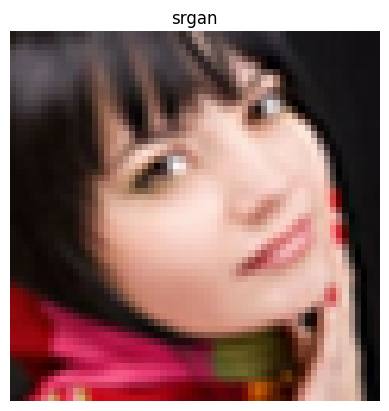

In [ ]:
# Plotting Low Resolution Image
plot_image(tf.squeeze(lr_image))